# Project 03: Volatility Forecasting & VaR Backtesting on European Markets

**Objective:** Design, validate, and benchmark out-of-sample 1-day-ahead conditional variance forecasts across two European equity indices (**EURO STOXX 50**, **FTSE MIB**) and one major FX pair (**EUR/USD**) over the 2009–2025 daily sample. 

In [1]:
from pathlib import Path
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
import statsmodels.api as sm
import yfinance as yf

In [2]:
# Configuration of first useful elements
tickers = ["^STOXX50E", "FTSEMIB.MI", "EURUSD=X"]
n_tickers = len(tickers)
start_date = "2009-01-01"
end_date = "2026-01-01"      # exclusive in yfinance: last available day is in December 2025
ohlc_tol_pct = 0.1           # tolerated OHLC inconsistency, in % of price (vendor feed noise)
spike_k = 4                  # spike threshold, in standard deviations of each series
ohl_cols = ["open", "high", "low"]
raw_parquet_path = Path("../data/raw_market_data_2009_2025.parquet")

# Functions that will be helpful
def log_returns_pct(close, ticker):
    """Daily log return in %, computed inside each ticker (needs rows sorted by ticker, date)."""
    return np.log(close / close.groupby(ticker).shift(1)) * 100

def ohlc_violation_pct(df):
    """How far Open/Close fall outside the [Low, High] range, in % of price (0 if consistent, NaN if OHL missing)."""
    above_high = np.maximum(0, np.maximum(df["open"], df["close"]) - df["high"]) / df["high"] * 100
    below_low = np.maximum(0, df["low"] - np.minimum(df["open"], df["close"])) / df["low"] * 100
    return np.maximum(above_high, below_low)

def spike_reversal_mask(df, k=spike_k):
    """Flags a return larger than k sigma that is almost fully reversed the next day (typical vendor error)."""
    grouped = df.groupby("ticker")["log_return_pct"]
    sigma = grouped.transform("std")
    r_t, r_next = df["log_return_pct"], grouped.shift(-1)
    return (
        (r_t.abs() > k * sigma)
        & (r_next.abs() > k * sigma)
        & (r_t * r_next < 0)
        & ((r_t + r_next).abs() < 1.5 * sigma)
    )

# Load or download the dataset
if raw_parquet_path.exists():
    market_data_wide = pd.read_parquet(raw_parquet_path)
else:
    raw_parquet_path.parent.mkdir(parents=True, exist_ok=True)
    market_data_wide = yf.download(
        tickers, start=start_date, end=end_date,
        auto_adjust=True, progress=False, multi_level_index=True,
    )
    market_data_wide.to_parquet(raw_parquet_path)

# Fromat Wide -> long, on the EURO STOXX 50 master calendar
master_dates = market_data_wide[("Close", "^STOXX50E")].dropna().index
market_data = (
    market_data_wide.loc[master_dates, ["Close", "High", "Low", "Open"]]
    .stack(level=1, future_stack=True)
    .rename_axis(index=["date", "ticker"], columns=None)
    .reset_index()
    .rename(columns=str.lower)
    .sort_values(["ticker", "date"])
    .reset_index(drop=True)
)

# Missing data: explicit flags, never silent
# Close missing on the master calendar = the asset did not trade that day (local holiday).
market_data["is_ffilled"] = market_data["close"].isna()
market_data["close"] = market_data.groupby("ticker")["close"].ffill()     # causal forward-fill
# Open/High/Low of a non-trading day stay NaN on purpose: no intraday information exists.

market_data["log_return_pct"] = log_returns_pct(market_data["close"], market_data["ticker"])

assert market_data["log_return_pct"].isna().sum() == n_tickers, "Only the first day of each ticker should have no return"
assert not market_data.duplicated(subset=["date", "ticker"]).any(), "Duplicate composite primary keys found"
assert market_data.groupby("ticker")["date"].apply(lambda s: s.is_monotonic_increasing).all(), "Non monotone dates in at least one ticker"

display(market_data)

,date,ticker,close,high,low,open,is_ffilled,log_return_pct
0,2009-01-05,EURUSD=X,1.364592,1.395790,1.355601,1.395790,False,NaN
1,2009-01-06,EURUSD=X,1.351004,1.363178,1.331806,1.363178,False,-1.000690
2,2009-01-07,EURUSD=X,1.361100,1.374193,1.343725,1.349947,False,0.744470
3,2009-01-08,EURUSD=X,1.369901,1.378436,1.353803,1.361341,False,0.644518
4,2009-01-09,EURUSD=X,1.345497,1.372476,1.341904,1.369976,False,-1.797497
...,...,...,...,...,...,...,...,...
12784,2025-12-19,^STOXX50E,5760.350098,5772.350098,5728.649902,5742.140137,False,0.324119
12785,2025-12-22,^STOXX50E,5743.689941,5770.990234,5733.790039,5754.390137,False,-0.289640
12786,2025-12-23,^STOXX50E,5749.279785,5754.529785,5729.339844,5742.560059,False,0.097274
12787,2025-12-29,^STOXX50E,5751.709961,5766.299805,5734.910156,5752.160156,False,0.042260


In [3]:
# Read-only diagnostics

# 1) Spike-and-reversal scan
display(market_data.loc[spike_reversal_mask(market_data)])

# Manual cross-check of the flagged day against the other index
dates_to_control = (
    (market_data["date"] >= "2020-03-10")
    & (market_data["date"] <= "2020-03-16")
    & market_data["ticker"].isin(["FTSEMIB.MI", "^STOXX50E"])
)
display(market_data.loc[dates_to_control])
# 2020-03-13 FTSEMIB.MI: verified genuine COVID-19 market rebound, concordant with ^STOXX50E

# 2) OHLC consistency: Open/Close must lie inside [Low, High]
violation_pct = ohlc_violation_pct(market_data)
violations = market_data.loc[violation_pct > ohlc_tol_pct].assign(
    ohlc_viol_pct=violation_pct,
    close_outside_range=lambda d: (d["close"] > d["high"]) | (d["close"] < d["low"]),
    open_outside_range=lambda d: (d["open"] > d["high"]) | (d["open"] < d["low"]),
)
display(violations)

,date,ticker,close,high,low,open,is_ffilled,log_return_pct
7066,2020-03-13,FTSEMIB.MI,15954.0,17545.0,15107.0,15108.0,False,6.875113


,date,ticker,close,high,low,open,is_ffilled,log_return_pct
7063,2020-03-10,FTSEMIB.MI,17870.000000,19175.000000,17772.000000,18654.000000,False,-3.334926
7064,2020-03-11,FTSEMIB.MI,17929.000000,18410.000000,17675.000000,18172.000000,False,0.329618
7065,2020-03-12,FTSEMIB.MI,14894.000000,17660.000000,14894.000000,17654.000000,False,-18.546107
7066,2020-03-13,FTSEMIB.MI,15954.000000,17545.000000,15107.000000,15108.000000,False,6.875113
7067,2020-03-16,FTSEMIB.MI,14980.000000,15699.000000,14153.000000,15697.000000,False,-6.299360
11326,2020-03-10,^STOXX50E,2910.020020,3088.570068,2896.739990,2973.610107,False,-1.671509
11327,2020-03-11,^STOXX50E,2905.560059,2998.649902,2893.429932,2924.929932,False,-0.153380
11328,2020-03-12,^STOXX50E,2545.229980,2883.250000,2535.889893,2883.250000,False,-13.240515
11329,2020-03-13,^STOXX50E,2586.020020,2793.270020,2537.270020,2584.360107,False,1.589901
11330,2020-03-16,^STOXX50E,2450.370117,2557.709961,2302.840088,2557.709961,False,-5.388094


,date,ticker,close,high,low,open,is_ffilled,log_return_pct,ohlc_viol_pct,close_outside_range,open_outside_range
34,2009-02-23,EURUSD=X,1.267813,1.298499,1.269487,1.279100,False,-1.989852,0.131850,True,False
375,2010-07-01,EURUSD=X,1.250750,1.224260,1.219899,1.223197,False,2.243496,2.163803,True,False
461,2010-10-29,EURUSD=X,1.377809,1.394117,1.380891,1.377695,False,0.000000,0.231453,True,True
1514,2015-01-26,EURUSD=X,1.112545,1.128399,1.114082,1.114082,False,-1.969567,0.137958,True,False
2807,2020-03-19,EURUSD=X,1.096155,1.094559,1.069793,1.094343,False,-0.491189,0.145788,True,False


In [4]:
# Repair policy (declared, rule-based, applied uniformly to every series):
#   a day is repaired when its Close lies outside [Low, High] by more than ohlc_tol_pct.
#   Close -> NaN -> causal forward-fill; Open/High/Low -> NaN (no reliable intraday information).
market_data["close_raw"] = market_data["close"]                      # audit trail for the sensitivity check
market_data["ohlc_viol_pct_raw"] = ohlc_violation_pct(market_data)

close_outside_range = (market_data["close"] > market_data["high"]) | (market_data["close"] < market_data["low"])
market_data["is_repaired"] = (market_data["ohlc_viol_pct_raw"] > ohlc_tol_pct) & close_outside_range

market_data.loc[market_data["is_repaired"], "close"] = np.nan
market_data["close"] = market_data.groupby("ticker")["close"].ffill()
market_data.loc[market_data["is_repaired"], ohl_cols] = np.nan

market_data["log_return_pct"] = log_returns_pct(market_data["close"], market_data["ticker"])

display(market_data.loc[market_data["is_repaired"]])

,date,ticker,close,high,low,open,is_ffilled,log_return_pct,close_raw,ohlc_viol_pct_raw,is_repaired
34,2009-02-23,EURUSD=X,1.293293,NaN,NaN,NaN,False,0.0,1.267813,0.131850,True
375,2010-07-01,EURUSD=X,1.223002,NaN,NaN,NaN,False,0.0,1.250750,2.163803,True
461,2010-10-29,EURUSD=X,1.377809,NaN,NaN,NaN,False,0.0,1.377809,0.231453,True
1514,2015-01-26,EURUSD=X,1.134675,NaN,NaN,NaN,False,0.0,1.112545,0.137958,True
2807,2020-03-19,EURUSD=X,1.101552,NaN,NaN,NaN,False,0.0,1.096155,0.145788,True


In [5]:
# Days whose return is not a clean one-day move: the asset did not trade, the Close was repaired,
# or the previous day was one of these (so the return spans a gap).
is_gap = market_data["is_ffilled"] | market_data["is_repaired"]
market_data["follows_gap"] = is_gap.groupby(market_data["ticker"]).shift(1, fill_value=False).astype(bool)

# Days on which a model may be scored (QLIKE needs a strictly positive variance proxy).
market_data["is_scorable"] = (
    market_data["log_return_pct"].notna()
    & (market_data["log_return_pct"] != 0)
    & ~is_gap
    & ~market_data["follows_gap"]
)

# Integrity checks
assert market_data["log_return_pct"].isna().sum() == n_tickers, "Only the first day of each ticker should have no return"
assert market_data.duplicated(subset=["date", "ticker"]).sum() == 0, "Duplicate composite primary keys found."
assert market_data.groupby("ticker")["date"].apply(lambda s: s.is_monotonic_increasing).all(), "Non monotone dates in at least one ticker"
assert market_data["close"].notna().all(), "Close must be fully populated after the forward-fill"
assert not (ohlc_violation_pct(market_data) > ohlc_tol_pct).any(), "OHLC violations above tolerance are still present"
verified_spikes = {("2020-03-13", "FTSEMIB.MI")}      # checked manually against ^STOXX50E: genuine COVID-19 rebound
flagged = market_data.loc[spike_reversal_mask(market_data), ["date", "ticker"]]
unexplained = [(d.strftime("%Y-%m-%d"), t) for d, t in zip(flagged["date"], flagged["ticker"])
               if (d.strftime("%Y-%m-%d"), t) not in verified_spikes]
assert not unexplained, f"Unexplained spike-and-reversal days: {unexplained}"

# Data quality summary
summary = market_data.groupby("ticker").agg(
    n_obs=("date", "size"),
    n_ffilled=("is_ffilled", "sum"),
    n_repaired=("is_repaired", "sum"),
    n_zero_return=("log_return_pct", lambda s: (s == 0).sum()),
    n_ohl_missing=("high", lambda s: s.isna().sum()),
    n_scorable=("is_scorable", "sum"),
)
display(summary)

# Sensitivity of the repair: how much does it move the statistics?
raw_returns = log_returns_pct(market_data["close_raw"], market_data["ticker"])
sensitivity = pd.DataFrame({
    "kurtosis_raw": raw_returns.groupby(market_data["ticker"]).agg(pd.Series.kurt),
    "kurtosis_repaired": market_data.groupby("ticker")["log_return_pct"].agg(pd.Series.kurt),
})
display(sensitivity)

# Freeze the clean dataset for the modelling notebooks
processed_path = Path("../data/market_data_clean_2009_2025.parquet")
market_data.to_parquet(processed_path, index=False)

,n_obs,n_ffilled,n_repaired,n_zero_return,n_ohl_missing,n_scorable
ticker,,,,,,
EURUSD=X,4263,5,5,26,10,4226
FTSEMIB.MI,4263,15,0,21,15,4226
^STOXX50E,4263,0,0,2,0,4260


,kurtosis_raw,kurtosis_repaired
ticker,,
EURUSD=X,2.324682,2.489399
FTSEMIB.MI,9.915339,9.915339
^STOXX50E,6.908443,6.908443


### Data Architecture, Vendor Quality Audit, and Cleaning

The universe comprises three European series: **EURO STOXX 50** (`^STOXX50E`), **FTSE MIB** (`FTSEMIB.MI`), and **EUR/USD** (`EURUSD=X`) from January 2009 to December 2025 (4,263 master-calendar trading days per series; 12,789 total observations).

To prevent look-ahead bias and silent data corruption, the ingestion pipeline enforces four explicit rules:
1. **Master Calendar & Non-Trading Days (`is_ffilled`):** All series are aligned to the `^STOXX50E` trading calendar. Missing closes on local holidays (15 days on `FTSEMIB.MI`, 5 days on `EURUSD=X`) are imputed via causal forward-fill, while `Open/High/Low` remain `NaN` so no artificial intraday range is fabricated.
2. **Spike-and-Reversal Scan:** A $4\sigma$ spike-and-reversal filter flags extreme 1-day jumps that immediately revert. The single flagged observation in 2009–2025 (`2020-03-13` on `FTSEMIB.MI`, $+6.88\%$) was cross-checked against `^STOXX50E` ($+1.59\%$ after a $-13.24\%$ crash on `2020-03-12`) and confirmed as a genuine COVID-19 market rebound.
3. **Rule-Based OHLC Consistency Repair (`is_repaired`):** Days where `Close` falls outside the `[Low, High]` range by more than the declared tolerance (`ohlc_tol_pct = 0.1%` of price) are flagged as vendor feed errors. Their `Close` is set to `NaN` and causally forward-filled, with `Open/High/Low` masked to `NaN`.
4. **Scorable Evaluation Mask (`is_scorable`):** Days with zero return, forward-filled holidays, repaired closes, and the day immediately following a gap are excluded from out-of-sample loss scoring (yielding 4,260 scorable days for `^STOXX50E` and 4,226 for `FTSEMIB.MI` and `EURUSD=X`), ensuring strictly positive and single-day variance proxies for `QLIKE`.

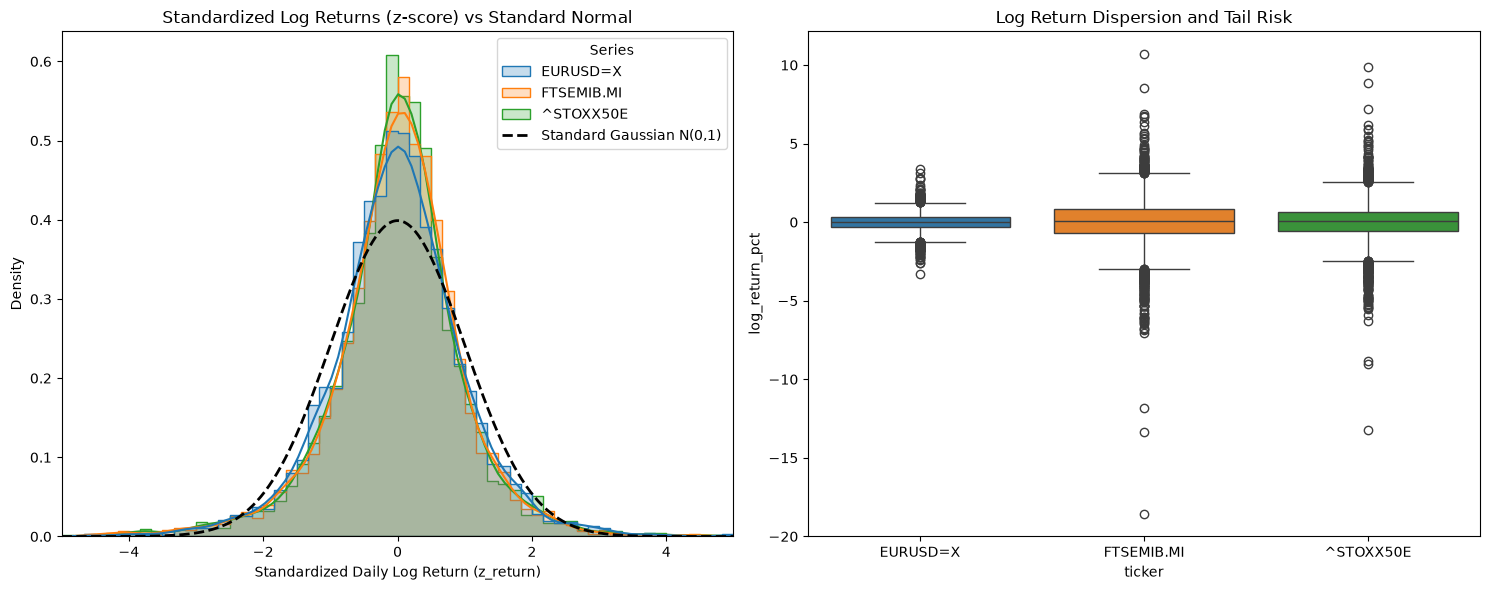

,excess_kurtosis,min_pct,max_pct,n_abs_gt_10
ticker,,,,
EURUSD=X,2.489399,-3.305597,3.400181,0
FTSEMIB.MI,9.915339,-18.546107,10.683984,4
^STOXX50E,6.908443,-13.240515,9.846568,1


In [6]:
# Graphical visualization of stylized facts
market_clean = market_data.dropna(subset=["log_return_pct"]).copy()
assert len(market_clean) == len(market_data) - n_tickers, "Only the first day of each ticker should be dropped"

# Standardized returns make the tails comparable across assets with very different volatility
market_clean["z_return"] = market_clean.groupby("ticker")["log_return_pct"].transform(lambda s: (s - s.mean()) / s.std())

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))

sns.histplot(data=market_clean, x="z_return", hue="ticker", element= "step", kde = True, bins = 60, binrange=(-5, 5), stat="density", common_norm=False, ax = axes[0])
x = np.linspace(-5, 5, 500)
axes[0].set_title("Standardized Log Returns (z-score) vs Standard Normal")
axes[0].set_xlabel("Standardized Daily Log Return (z_return)")
axes[0].set_xlim(-5, 5)
sns_leg = axes[0].get_legend()
handles = sns_leg.legend_handles if sns_leg else []
labels = [t.get_text() for t in sns_leg.get_texts()] if sns_leg else []

gauss_line, = axes[0].plot(
    x, stats.norm.pdf(x, loc=0, scale=1),
    color="black", linestyle="--", linewidth=2, label="Standard Gaussian N(0,1)"
)
axes[0].legend(handles=handles + [gauss_line], labels=labels + ["Standard Gaussian N(0,1)"], title="Series")

sns.boxplot(data=market_clean, x="ticker", y="log_return_pct", hue="ticker", ax=axes[1])
axes[1].set_title("Log Return Dispersion and Tail Risk")

plt.tight_layout()
plt.show()

tail_summary = market_clean.groupby("ticker")["log_return_pct"].agg(
    excess_kurtosis="kurt",
    min_pct="min",
    max_pct="max",
    n_abs_gt_10=lambda s: (s.abs() > 10).sum(),
)
display(tail_summary)

### Stylized Fact 1: Fat Tails and Leptokurtosis

The empirical distribution of daily log-returns (2009–2025) deviates from the Gaussian assumption across all three series, with **Excess Kurtosis (Fisher)** equal to **6.91** (`^STOXX50E`), **9.91** (`FTSEMIB.MI`), and **2.49** (`EURUSD=X`). 

As shown in the Boxplot, extreme tail events in the equity indices (shocks exceeding $\pm 10\%$ during the 2009–2025 sample, which includes the Sovereign Debt Crisis and COVID-19) occur far more frequently than a normal distribution predicts. This excess kurtosis is consistent with heavy-tailed innovations and motivates the use of **Student-t distributions** in the volatility models.

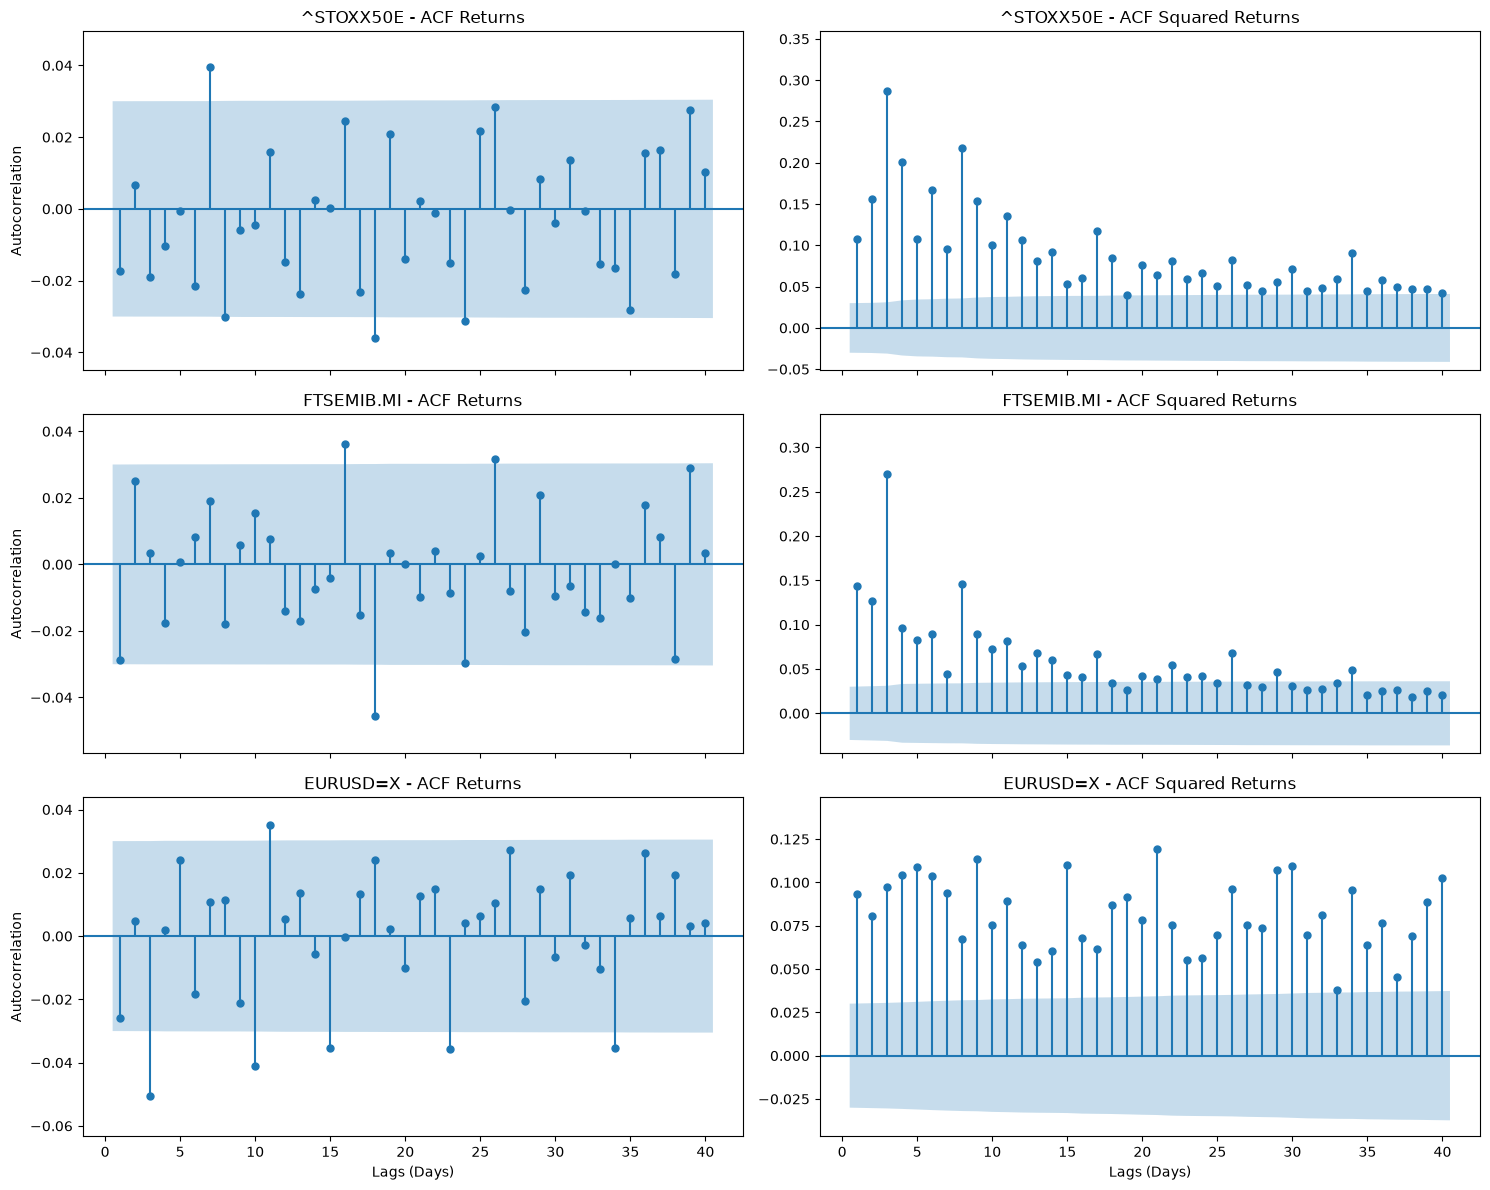

In [7]:
# Autocorrelation function (ACF) of returns and squared returns
fig, axes = plt.subplots(nrows=n_tickers, ncols=2, figsize=(15, 4 * n_tickers), sharex=True)

for i, ticker in enumerate(tickers):
    ticker_returns = market_clean.loc[market_clean["ticker"] == ticker, "log_return_pct"]

    sm.graphics.tsa.plot_acf(ticker_returns, lags=40, ax=axes[i, 0], alpha=0.05, zero=False, auto_ylims=True)
    axes[i, 0].set_title(f"{ticker} - ACF Returns")
    axes[i, 0].set_ylabel("Autocorrelation")

    sm.graphics.tsa.plot_acf(ticker_returns ** 2, lags=40, ax=axes[i, 1], alpha=0.05, zero=False, auto_ylims=True)
    axes[i, 1].set_title(f"{ticker} - ACF Squared Returns")

axes[-1, 0].set_xlabel("Lags (Days)")
axes[-1, 1].set_xlabel("Lags (Days)")

plt.tight_layout()
plt.show()

### Stylized Fact 2: Volatility Clustering and Linear Predictability

The Autocorrelation Function (ACF) analysis highlights two classical stylized facts of financial time series:
1. **Linear Predictability (ACF on Log Returns):** Autocorrelations of raw returns $r_t$ are close to zero across all three series. While a few isolated lags marginally cross the 95% Gaussian confidence bands, these bands are overly narrow under heavy-tailed distributions.
2. **Volatility Clustering (ACF on Squared Returns):** The autocorrelation of squared returns $r_t^2$ is positive and decays slowly over 40 lags for `^STOXX50E` and `FTSEMIB.MI`, while remaining flat and persistent for `EURUSD=X`. This confirms that return magnitude is path-dependent, motivating **GARCH(1,1)** parameterization.

In [8]:
# Leverage effect: do negative returns today predict higher squared returns tomorrow?
market_clean["next_sqrd_log_return"] = market_clean.groupby("ticker")["log_return_pct"].shift(-1) ** 2
assert market_clean["next_sqrd_log_return"].isna().sum() == n_tickers, "Only the last day of each ticker should have no next-day return"

leverage_effect = duckdb.sql("""
SELECT ticker,
       CORR(log_return_pct, next_sqrd_log_return) AS leverage_corr,
       AVG(CASE WHEN log_return_pct < 0 THEN next_sqrd_log_return END) AS mean_sq_after_neg,
       AVG(CASE WHEN log_return_pct > 0 THEN next_sqrd_log_return END) AS mean_sq_after_pos
FROM market_clean
GROUP BY ticker
""").df().set_index("ticker")

assert leverage_effect.shape == (n_tickers, 3), "Unexpected shape of the leverage table"

# Sanity expectations from the literature on equity indices (not integrity checks): if they fail, investigate before going on
for equity_index in ["^STOXX50E", "FTSEMIB.MI"]:
    row = leverage_effect.loc[equity_index]
    assert row["leverage_corr"] < 0, f"Expectation violated on {equity_index}: correlation should be negative"
    assert row["mean_sq_after_neg"] > row["mean_sq_after_pos"], f"Expectation violated on {equity_index}: squared returns should be higher after negative days"

display(leverage_effect)

,leverage_corr,mean_sq_after_neg,mean_sq_after_pos
ticker,,,
EURUSD=X,0.002454,0.311034,0.309277
^STOXX50E,-0.083978,1.984480,1.434662
FTSEMIB.MI,-0.078816,2.713474,1.982259


### Stylized Fact 3: Leverage Effect

The cross-correlation $\text{Corr}(r_t, r_{t+1}^2)$ between daily returns and next-day squared returns highlights a clear structural difference between equity indices and foreign exchange:
* **Equity Indices (`^STOXX50E`: -0.084, `FTSEMIB.MI`: -0.079):** Mean squared returns following a negative return day are ~38% higher than those following a positive return day (`1.98` vs `1.43` for `^STOXX50E`; `2.71` vs `1.98` for `FTSEMIB.MI`). This negative asymmetry is consistent with the financial leverage effect and motivates testing the asymmetric **GJR-GARCH** specification.
* **Foreign Exchange (`EURUSD=X`: 0.0025):** Conditional next-day squared returns are virtually identical after negative (`0.311`) and positive (`0.309`) days, reflecting the symmetric relative nature of an exchange rate pair.